In [1]:
%reset -f
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import binned_statistic_2d
from datetime import datetime

import sys
sys.path.append("../../tools")
import functions as func

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import importlib
#importlib.reload(prep)


In [3]:
load_dir1 = Path(f"../../saved_models/sta_entropy_15fold/sp3to20_MD_transpt3_r9")
load_dir2 = Path(f"../../saved_models/diversity_15fold/sp3to20_MD_transpt3_r1")
load_dir3 = Path(f"../../saved_models/num_stable_states_15fold/sp3to20_NS_transpt3_r7")
emodel = func.load_saved_model_MD(load_dir1, device)
dmodel = func.load_saved_model_MD(load_dir2, device)
epredictor = func.Predictor(emodel)
dpredictor = func.Predictor(dmodel)
MaxNum = emodel["NumSpecies"]


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [ ]:
df = pd.read_csv("gamma5.csv")
#df = pd.read_csv("gamma5_neg.csv")
df = df.dropna()
df = df[df["richness"] >= 4]

# Column names
col_pos = "pos_inall"
col_density = "density"
col_richness = "richness"

density_bins = [0, 0.3, 0.7, 1]
pos_bins = [0, 0.2, 0.4, 0.6, 0.8, 1]
# density_bins = [0, 0.3, 0.7, 1]
# pos_bins = [0, 0.16, 0.38, 0.6, 0.8, 1]

df["density_bin"] = pd.cut(
    df[col_density],
    bins=density_bins,
    include_lowest=True
)
df["pos_bin"] = pd.cut(
    df[col_pos],
    bins=pos_bins,
    include_lowest=True
)
df[col_richness] = df[col_richness].astype(int)

data_dict = {}

for (dens_bin, pos_bin), sub_df_all in df.groupby(["density_bin", "pos_bin"]):
    print(dens_bin, pos_bin, len(sub_df_all))

    all_species = []
    all_gamma_mean = []
    all_gamma_neg_mean = []
    all_rela_H = []
    all_entropy = []
    all_rela_D = []
    all_diversity = []

    for spe, sub_df in sub_df_all.groupby(col_richness):

        Xnum_pad = sub_df.iloc[:, :(MaxNum**2+MaxNum)].values
        gamma_mean = sub_df["gamma_mean"].values # mean of only non-zero interactions
        gamma_neg_mean = sub_df["gamma_neg_mean"].values # mean of only negative interactions

        # Entropy
        relative_H = epredictor.predict_array_MD(Xnum_pad, device)
        entropy = relative_H*(spe-1)+1

        # Relative Diversity
        relative_D = dpredictor.predict_array_MD(Xnum_pad, device)
        diversity = relative_D*(spe-1)+1

        all_species.append(np.full_like(relative_H, spe, dtype=int))
        all_gamma_mean.append(gamma_mean)
        all_gamma_neg_mean.append(gamma_neg_mean)
        all_rela_H.append(relative_H.copy())
        all_entropy.append(entropy.copy())
        all_rela_D.append(relative_D.copy())
        all_diversity.append(diversity.copy())

    if len(all_species) == 0:
        continue

    all_species = np.concatenate(all_species)
    all_gamma_mean = np.concatenate(all_gamma_mean)
    all_gamma_neg_mean = np.concatenate(all_gamma_neg_mean)
    all_rela_H = np.concatenate(all_rela_H)
    all_entropy = np.concatenate(all_entropy)
    all_rela_D = np.concatenate(all_rela_D)
    all_diversity = np.concatenate(all_diversity)

    data_dict[(dens_bin, pos_bin)] = {
        "all_species": all_species,
        "all_gamma_mean": all_gamma_mean,
        "all_gamma_neg_mean": all_gamma_neg_mean,
        "all_rela_H": all_rela_H, # Relative entropy
        "all_entropy": all_entropy, # Entropy
        "all_rela_D": all_rela_D,
        "all_diversity": all_diversity
    }


C:\Users\HW\AppData\Local\Temp\ipykernel_9536\2654689517.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for (dens_bin, pos_bin), sub_df_all in df.groupby(["density_bin", "pos_bin"]):


(-0.001, 0.3] (-0.001, 0.16] 8244
(-0.001, 0.3] (0.16, 0.38] 8224
(-0.001, 0.3] (0.38, 0.6] 8660
(-0.001, 0.3] (0.6, 0.8] 7359
(-0.001, 0.3] (0.8, 1.0] 8325
(0.3, 0.7] (-0.001, 0.16] 8764
(0.3, 0.7] (0.16, 0.38] 12163
(0.3, 0.7] (0.38, 0.6] 12476
(0.3, 0.7] (0.6, 0.8] 11014
(0.3, 0.7] (0.8, 1.0] 10679
(0.7, 1.0] (-0.001, 0.16] 6377
(0.7, 1.0] (0.16, 0.38] 8920
(0.7, 1.0] (0.38, 0.6] 8780
(0.7, 1.0] (0.6, 0.8] 8163
(0.7, 1.0] (0.8, 1.0] 7852


In [16]:
def top_75_mean(values):
    if len(values) == 0:
        return np.nan
    
    values_sorted = np.sort(values)[::-1]   # descending order
    k = int(np.ceil(1 * len(values)))
    
    return np.mean(values_sorted[:k])

cmap = LinearSegmentedColormap.from_list(
    "custom_cmap",
    ["#e8d7f1", "#4a306d"]
)

# cmapsta = LinearSegmentedColormap.from_list(
#     "custom_cmap",
#     ["#fff8cd", "#e38458", "#d4551a"]
# )

cmapsta = LinearSegmentedColormap.from_list(
    "custom_cmap",
    ["#fff8cd", "#d4551a"]
)

cmapdiv = LinearSegmentedColormap.from_list(
    "custom_cmap",
    ["#ffef96", "#e6f8f4", "#67c6d7"]
)

plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis label (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border line width
    'legend.fontsize': 7, # legend (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick label (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})


**Relative entropy**

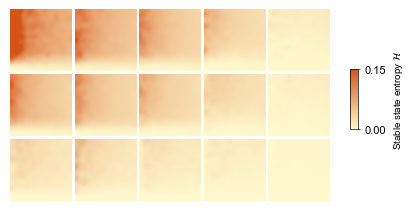

In [22]:
density_list = list(df["density_bin"].cat.categories)
pos_list = list(df["pos_bin"].cat.categories)

n_rows = len(density_list)
n_cols = len(pos_list)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(0.8*n_cols, 0.8*n_rows),
    sharex=True,
    sharey=True
)

if n_rows == 1:
    axes = axes[np.newaxis, :]
if n_cols == 1:
    axes = axes[:, np.newaxis]

colorbar_min = 0
colorbar_max = 0.15

for i, dens in enumerate(density_list[::-1]):
    for j, pos in enumerate(pos_list):

        ax = axes[i, j]

        if (dens, pos) not in data_dict:
            ax.axis("off")
            continue

        data = data_dict[(dens, pos)]
        mask = (
            ~np.isnan(data["all_species"]) &
            ~np.isnan(data["all_gamma_neg_mean"]) &
            ~np.isnan(data["all_rela_H"])
        )

        xlabel = data["all_species"][mask]
        ylabel = data["all_gamma_neg_mean"][mask]
        clabel = data["all_rela_H"][mask]

        stat, x_edge, y_edge, _ = binned_statistic_2d(
            xlabel,
            ylabel,
            clabel,
            statistic=top_75_mean,
            bins=[17,17],
            range=[[4, 20], [0.1, 7]]
        )

        im = ax.imshow(
            stat.T,
            origin="lower", # define (0,0) at the lower-left corner
            aspect="auto", # each pixel automatically stretches to fill the axes
            #cmap="OrRd",
            cmap=cmapsta, 
            #cmap=cmapdiv,
            interpolation='bicubic', # interpolation smoothing
            extent=[
                x_edge[0], x_edge[-1],
                y_edge[0], y_edge[-1]
            ], # actual coordinate range that scatter points map to
            
            vmin=colorbar_min, # colorbar range, control the lower bound for the lightest color
            vmax=colorbar_max
        )
        ax.set_box_aspect(1)
        ax.set_xticks([]) # hide tick labels
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False) # keep or hide the border

fig.subplots_adjust(
    left=0,
    right=0.8,
    bottom=0.2,
    top=1,
    wspace=0.05, # horizontal spacing between subplots
    hspace=0.05 # vertical spacing between subplots
)

cbar_ax = fig.add_axes([0.85, 0.5, 0.02, 0.25]) # colorbar [left, bottom, width, height] in figure percentage
cbar = fig.colorbar(im, cax=cbar_ax, ticks=[colorbar_min, colorbar_max])
cbar.set_label(r"Stable state entropy $\mathcal{H}$",fontsize=7)

plt.savefig(
    f"phase_H_relative5_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight',
    transparent=True
)

plt.show()


**Relative diversity**

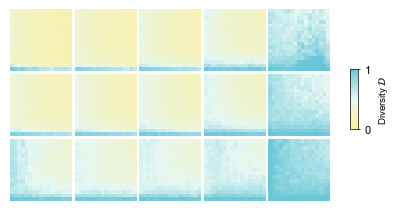

In [28]:
density_list = list(df["density_bin"].cat.categories)
pos_list = list(df["pos_bin"].cat.categories)

n_rows = len(density_list)
n_cols = len(pos_list)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(0.8*n_cols, 0.8*n_rows),
    sharex=True,
    sharey=True
)

if n_rows == 1:
    axes = axes[np.newaxis, :]
if n_cols == 1:
    axes = axes[:, np.newaxis]

colorbar_min = 0
colorbar_max = 1

for i, dens in enumerate(density_list[::-1]):
    for j, pos in enumerate(pos_list):

        ax = axes[i, j]

        if (dens, pos) not in data_dict:
            ax.axis("off")
            continue

        data = data_dict[(dens, pos)]
        mask = (
            ~np.isnan(data["all_species"]) &
            ~np.isnan(data["all_gamma_neg_mean"]) &
            ~np.isnan(data["all_rela_D"])
        )

        xlabel = data["all_species"][mask]
        ylabel = data["all_gamma_neg_mean"][mask]
        clabel = data["all_rela_D"][mask]

        stat, x_edge, y_edge, _ = binned_statistic_2d(
            xlabel,
            ylabel,
            clabel,
            statistic=top_75_mean,
            bins=[17,17],
            range=[[4, 20], [0.1, 7]]
        )

        im = ax.imshow(
            stat.T,
            origin="lower", # define (0,0) at the lower-left corner
            aspect="auto", # each pixel automatically stretches to fill the axes
            #cmap="OrRd",
            #cmap=cmapsta, 
            cmap=cmapdiv,
            #interpolation='bicubic', # interpolation smoothing
            extent=[
                x_edge[0], x_edge[-1],
                y_edge[0], y_edge[-1]
            ], # actual coordinate range that scatter points map to
            
            vmin=colorbar_min, # colorbar range, control the lower bound for the lightest color
            vmax=colorbar_max
        )
        ax.set_box_aspect(1)
        ax.set_xticks([]) # hide tick labels
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False) # keep or hide the border

fig.subplots_adjust(
    left=0,
    right=0.8,
    bottom=0.2,
    top=1,
    wspace=0.05, # horizontal spacing between subplots
    hspace=0.05 # vertical spacing between subplots
)

cbar_ax = fig.add_axes([0.85, 0.5, 0.02, 0.25]) # colorbar [left, bottom, width, height] in figure percentage
cbar = fig.colorbar(im, cax=cbar_ax, ticks=[colorbar_min, colorbar_max])
cbar.set_label(r"Diversity $\mathcal{D}$",fontsize=7)

plt.savefig(
    f"phase_D_relative5_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight',
    transparent=True
)

plt.show()


**Entropy**

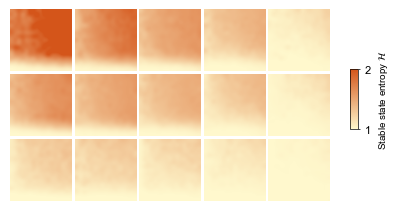

In [24]:
density_list = list(df["density_bin"].cat.categories)
pos_list = list(df["pos_bin"].cat.categories)

n_rows = len(density_list)
n_cols = len(pos_list)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(0.8*n_cols, 0.8*n_rows),
    sharex=True,
    sharey=True
)

if n_rows == 1:
    axes = axes[np.newaxis, :]
if n_cols == 1:
    axes = axes[:, np.newaxis]

colorbar_min = 1
colorbar_max = 2

for i, dens in enumerate(density_list[::-1]):
    for j, pos in enumerate(pos_list):

        ax = axes[i, j]

        if (dens, pos) not in data_dict:
            ax.axis("off")
            continue

        data = data_dict[(dens, pos)]
        mask = (
            ~np.isnan(data["all_species"]) &
            ~np.isnan(data["all_gamma_neg_mean"]) &
            ~np.isnan(data["all_entropy"])
        )

        xlabel = data["all_species"][mask]
        ylabel = data["all_gamma_neg_mean"][mask]
        clabel = data["all_entropy"][mask]

        stat, x_edge, y_edge, _ = binned_statistic_2d(
            xlabel,
            ylabel,
            clabel,
            statistic=top_75_mean,
            bins=[17,17],
            range=[[4, 20], [0.1, 7]]
        )

        im = ax.imshow(
            stat.T,
            origin="lower", # define (0,0) at the lower-left corner
            aspect="auto", # each pixel automatically stretches to fill the axes
            #cmap="OrRd",
            cmap=cmapsta, 
            #cmap=cmapdiv,
            interpolation='bicubic', # interpolation smoothing
            extent=[
                x_edge[0], x_edge[-1],
                y_edge[0], y_edge[-1]
            ], # actual coordinate range that scatter points map to
            
            vmin=colorbar_min, # colorbar range, control the lower bound for the lightest color
            vmax=colorbar_max
        )
        ax.set_box_aspect(1)
        ax.set_xticks([]) # hide tick labels
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False) # keep or hide the border

fig.subplots_adjust(
    left=0,
    right=0.8,
    bottom=0.2,
    top=1,
    wspace=0.05, # horizontal spacing between subplots
    hspace=0.05 # vertical spacing between subplots
)

cbar_ax = fig.add_axes([0.85, 0.5, 0.02, 0.25]) # colorbar [left, bottom, width, height] in figure percentage
cbar = fig.colorbar(im, cax=cbar_ax, ticks=[colorbar_min, colorbar_max])
cbar.set_label(r"Stable state entropy $\mathcal{H}$",fontsize=7)

plt.savefig(
    f"phase_H_real5_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight',
    transparent=True
)

plt.show()


**Diversity**

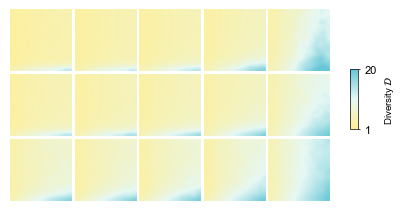

In [25]:
density_list = list(df["density_bin"].cat.categories)
pos_list = list(df["pos_bin"].cat.categories)

n_rows = len(density_list)
n_cols = len(pos_list)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(0.8*n_cols, 0.8*n_rows),
    sharex=True,
    sharey=True
)

if n_rows == 1:
    axes = axes[np.newaxis, :]
if n_cols == 1:
    axes = axes[:, np.newaxis]

colorbar_min = 1
colorbar_max = 20

for i, dens in enumerate(density_list[::-1]):
    for j, pos in enumerate(pos_list):

        ax = axes[i, j]

        if (dens, pos) not in data_dict:
            ax.axis("off")
            continue

        data = data_dict[(dens, pos)]
        mask = (
            ~np.isnan(data["all_species"]) &
            ~np.isnan(data["all_gamma_neg_mean"]) &
            ~np.isnan(data["all_diversity"])
        )

        xlabel = data["all_species"][mask]
        ylabel = data["all_gamma_neg_mean"][mask]
        clabel = data["all_diversity"][mask]

        stat, x_edge, y_edge, _ = binned_statistic_2d(
            xlabel,
            ylabel,
            clabel,
            statistic=top_75_mean,
            bins=[17,17],
            range=[[4, 20], [0.1, 7]]
        )

        im = ax.imshow(
            stat.T,
            origin="lower", # define (0,0) at the lower-left corner
            aspect="auto", # each pixel automatically stretches to fill the axes
            #cmap="OrRd",
            #cmap=cmapsta, 
            cmap=cmapdiv,
            interpolation='bicubic', # interpolation smoothing
            extent=[
                x_edge[0], x_edge[-1],
                y_edge[0], y_edge[-1]
            ], # actual coordinate range that scatter points map to
            
            vmin=colorbar_min, # colorbar range, control the lower bound for the lightest color
            vmax=colorbar_max
        )
        ax.set_box_aspect(1)
        ax.set_xticks([]) # hide tick labels
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False) # keep or hide the border

fig.subplots_adjust(
    left=0,
    right=0.8,
    bottom=0.2,
    top=1,
    wspace=0.05, # horizontal spacing between subplots
    hspace=0.05 # vertical spacing between subplots
)

cbar_ax = fig.add_axes([0.85, 0.5, 0.02, 0.25]) # colorbar [left, bottom, width, height] in figure percentage
cbar = fig.colorbar(im, cax=cbar_ax, ticks=[colorbar_min, colorbar_max])
cbar.set_label(r"Diversity $\mathcal{D}$",fontsize=7)

plt.savefig(
    f"phase_D_real5_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight',
    transparent=True
)

plt.show()
